# Solving the n-Queens Problem using Local Search

Student Name: [Add your name]

I have used the following AI tools: [list tools]

I understand that my submission needs to be my own work: [your initials]


## Learning Outcomes

* Implement multiple hill climbing search variants to solve the n-Queens problem.
* Apply simulated annealing with appropriate temperature scheduling to overcome local optima.
* Compare algorithm performance using runtime, solution quality, and success rate metrics.
* Analyze and visualize algorithm performance across different problem sizes.
* Graduate Students: Design and test alternative local move operators to improve search efficiency.

## Instructions

Total Points: Undergrads 100 + 5 bonus / Graduate students 110

Complete this notebook. Use the provided notebook cells and insert additional code and markdown cells as needed. Submit the completely rendered notebook as a HTML file. 

In [1]:
# change directory to Google Drive for Google Colab
try:
    from google.colab import drive
    import os

    drive.mount('/content/drive')
    os.chdir('/content/drive/My Drive/Colab Notebooks/')
    print("Your working directory is now Google Drive: My Drive > Colab Notebooks")
except ImportError:
    pass

## The n-Queens Problem

* __Goal:__ Find an arrangement of $n$ queens on a $n \times n$ chess board so that no queen is on the same row, column or diagonal as any other queen.

* __State space:__ An arrangement of the queens on the board. We restrict the state space to arrangements where there is only a single queen per column. We represent a state as an integer vector $\mathbf{q} = \{q_1, q_2, \dots, q_n\}$, each number representing the row positions of the queens from left to right. We will call a state a "board."

* __Objective function:__ The number of pairwise conflicts (i.e., two queens in the same row/column/diagonal).
The optimization problem is to find the optimal arrangement $\mathbf{q}^*$ of $n$ queens on the board can be written as:

  > minimize: $\mathrm{conflicts}(\mathbf{q})$
  >
  > subject to: $\mathbf{q} \ \text{contains only one queen per column}$

  Note: the constraint (subject to) is enforced by the definition of the state space.

* __Local improvement move:__ Move one queen to a different row in its column.

* __Termination:__ For this problem there is always an arrangement $\mathbf{q}^*$ with $\mathrm{conflicts}(\mathbf{q}^*) = 0$, however, the local improvement moves might end up in a local minimum. 

## Helper functions

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

np.random.seed(1234)


def random_board(n):
    """Creates a random board of size n x n. Note that only a single queen is placed in each column!"""
    
    return(np.random.randint(0,n, size = n))

def comb2(n): return n*(n-1)//2 # this is n choose 2 equivalent to math.comb(n, 2); // is int division

def conflicts(board):
    """Calculate the number of conflicts, i.e., the objective function."""

    n = len(board)
    
    horizontal_cnt = [0] * n
    diagonal1_cnt = [0] * 2 * n
    diagonal2_cnt = [0] * 2 * n
    
    for i in range(n):
        horizontal_cnt[board[i]] += 1
        diagonal1_cnt[i + board[i]] += 1
        diagonal2_cnt[i - board[i] + n] += 1
    
    return sum(map(comb2, horizontal_cnt + diagonal1_cnt + diagonal2_cnt))

# decrease the font size to fit larger boards
def show_board(board, cols = ['white', 'gray'], fontsize = 48):  
    """display the board"""
    
    n = len(board)
    
    # create chess board display
    display = np.zeros([n,n])
    for i in range(n):
        for j in range(n):
            if (((i+j) % 2) != 0): 
                display[i,j] = 1
    
    cmap = colors.ListedColormap(cols)
    fig, ax = plt.subplots()
    ax.imshow(display, cmap = cmap, 
              norm = colors.BoundaryNorm(range(len(cols)+1), cmap.N))
    ax.set_xticks([])
    ax.set_yticks([])
    
    # place queens. Note: Unicode u265B is a black queen
    for j in range(n):
        plt.text(j, board[j], u"\u265B", fontsize = fontsize, 
                 horizontalalignment = 'center',
                 verticalalignment = 'center')
    
    print(f"Board with {conflicts(board)} conflicts.")
    plt.show()

## Create a board

Board with 4 conflicts.


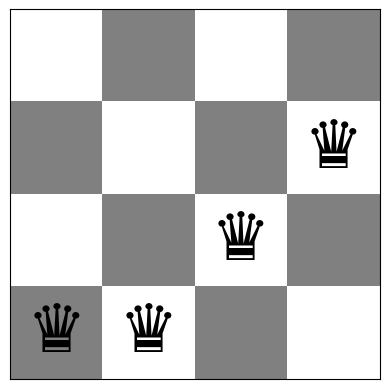

Queens (left to right) are at rows: [3 3 2 1]
Number of conflicts: 4


In [3]:
board = random_board(4)

show_board(board)
print(f"Queens (left to right) are at rows: {board}")
print(f"Number of conflicts: {conflicts(board)}")

A board $4 \times 4$ with no conflicts:

Board with 0 conflicts.


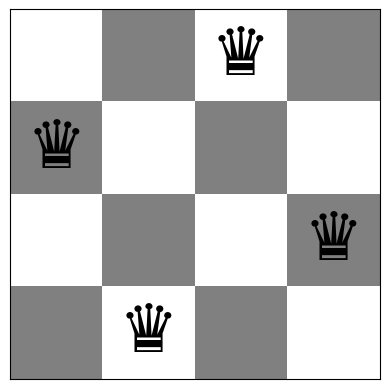

In [4]:
board = [1,3,0,2]
show_board(board)

# Tasks

## General [10 Points]

1. Make sure that you use the latest version of this notebook. Sync your forked repository and pull the latest revision. 
2. Your implementation can use libraries like math, numpy, scipy, but not libraries that implement intelligent agents or complete search algorithms. Try to keep the code simple! In this course, we want to learn about the algorithms and we often do not need to use object-oriented design.
3. You notebook needs to be formatted professionally. 
    - Add additional markdown blocks for your description, comments in the code, add tables and use mathplotlib to produce charts where appropriate
    - Do not show debugging output or include an excessive amount of output.
    - Check that your submitted file is readable and contains all figures.
4. Document your code. Use comments in the code and add a discussion of how your implementation works and your design choices.

## Task 1: Steepest-ascend Hill Climbing Search [20 Points]

Calculate the objective function for all local moves (see definition of local moves above) and always choose the best among all local moves. If there are no local moves that improve the objective, then you have reached a local optimum. 

4-Queens: Khởi tạo h=4 -> Kết quả h=0, Bước=2, Thành công=True
Board with 0 conflicts.


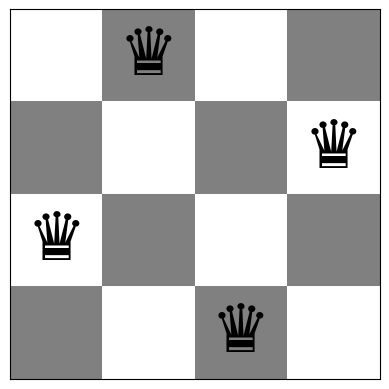

8-Queens: Khởi tạo h=5 -> Kết quả h=1, Bước=3, Thành công=False
Board with 1 conflicts.


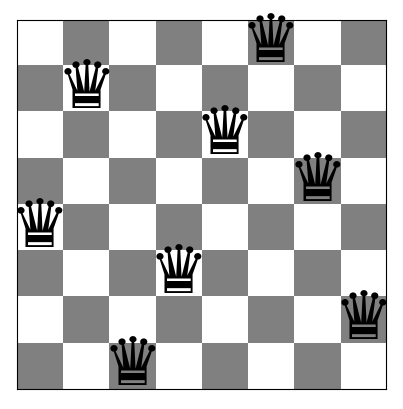

In [5]:
# Task 1: Steepest-Ascent Hill Climbing Implementation
def steepest_ascent_hill_climbing(board, max_steps=1000):
    """
    Đánh giá tất cả n * (n - 1) nước đi lân cận cục bộ và luôn chọn nước đi có số xung đột nhỏ nhất.
    Dừng khi không có nước đi nào cải thiện số xung đột (chạm cực trị địa phương hoặc cao nguyên).
    """
    n = len(board)
    current_board = np.array(board, copy=True)
    current_h = conflicts(current_board)
    history = [current_h]
    evaluations = 1
    steps = 0
    
    while steps < max_steps and current_h > 0:
        best_board = None
        best_h = current_h
        
        for col in range(n):
            current_row = current_board[col]
            for row in range(n):
                if row == current_row:
                    continue
                neighbor = np.array(current_board, copy=True)
                neighbor[col] = row
                h = conflicts(neighbor)
                evaluations += 1
                if h < best_h:
                    best_h = h
                    best_board = neighbor
                    
        if best_h < current_h:
            current_board = best_board
            current_h = best_h
            history.append(current_h)
            steps += 1
        else:
            break
            
    return {
        'board': current_board,
        'conflicts': current_h,
        'steps': steps,
        'evaluations': evaluations,
        'history': history,
        'success': (current_h == 0)
    }

# Thử nghiệm trên bàn cờ 4-Queens và 8-Queens
test_b4 = random_board(4)
res_s4 = steepest_ascent_hill_climbing(test_b4)
print(f"4-Queens: Khởi tạo h={conflicts(test_b4)} -> Kết quả h={res_s4['conflicts']}, Bước={res_s4['steps']}, Thành công={res_s4['success']}")
show_board(res_s4['board'])

test_b8 = random_board(8)
res_s8 = steepest_ascent_hill_climbing(test_b8)
print(f"8-Queens: Khởi tạo h={conflicts(test_b8)} -> Kết quả h={res_s8['conflicts']}, Bước={res_s8['steps']}, Thành công={res_s8['success']}")
show_board(res_s8['board'])


## Task 2: Inefficient Stochastic Hill Climbing [10 Points]

Modify the algorithm for steepest-ascend hill climbing by choosing randomly from among all uphill moves till you have reached a local optimum.

In [6]:
# Task 2: Inefficient Stochastic Hill Climbing
def inefficient_stochastic_hill_climbing(board, max_steps=1000):
    """
    Đánh giá toàn bộ n * (n - 1) nước đi lân cận, lọc ra tất cả các nước đi làm giảm xung đột (uphill/improving),
    sau đó chọn ngẫu nhiên 1 trong các nước đi cải thiện này cho đến khi gặp cực trị địa phương.
    """
    n = len(board)
    current_board = np.array(board, copy=True)
    current_h = conflicts(current_board)
    history = [current_h]
    evaluations = 1
    steps = 0
    
    while steps < max_steps and current_h > 0:
        improving_moves = []
        for col in range(n):
            current_row = current_board[col]
            for row in range(n):
                if row == current_row:
                    continue
                neighbor = np.array(current_board, copy=True)
                neighbor[col] = row
                h = conflicts(neighbor)
                evaluations += 1
                if h < current_h:
                    improving_moves.append((neighbor, h))
                    
        if len(improving_moves) > 0:
            idx = np.random.randint(len(improving_moves))
            current_board, current_h = improving_moves[idx]
            history.append(current_h)
            steps += 1
        else:
            break
            
    return {
        'board': current_board,
        'conflicts': current_h,
        'steps': steps,
        'evaluations': evaluations,
        'history': history,
        'success': (current_h == 0)
    }

res_in8 = inefficient_stochastic_hill_climbing(test_b8)
print(f"Inefficient Stochastic 8-Queens: h_cuối={res_in8['conflicts']}, bước={res_in8['steps']}, số lần đánh giá={res_in8['evaluations']}")


Inefficient Stochastic 8-Queens: h_cuối=1, bước=3, số lần đánh giá=225


__Important note:__ This is a very expensive algorithm since it has to calculate the objective function (number of conflicts) for all possible moves. The next algorithm produces the same result, but with much less computational cost.

## Task 3: Efficient Stochastic Hill Climbing [20 Points]

Stochastic hill climbing is in practice always implemented in the following way: 

1. Generate only a single random local neighbor at a time.
2. Accept the move if it has a better objective function value than the current state. 
3. Repeat till a stopping criterion is met.

This is very efficient if each state has many possible successor states. This method is called "First-choice hill climbing" in the textbook and in practice this is just called "Stochastic Hill Climbing."

__Notes:__ 

* Detecting local optima is tricky since you never calculate the objective function for all local moves! A popular option is to stop if you were not able to improve the objective function during the last $x$ tries. You will need to argue what the right number for $x$ is. It will depend on the size of the board. Hint: You are sampling random local moves from the set of all possible moves with replacement and you want to make sure that you trie almost all before you stop.

In [7]:
# Task 3: Efficient Stochastic Hill Climbing (First-Choice Hill Climbing)
def efficient_stochastic_hill_climbing(board, max_steps=5000):
    """
    Chỉ sinh từng lân cận ngẫu nhiên một. Chấp nhận ngay lập tức nếu lân cận đó cải thiện hàm mục tiêu.
    Dừng khi sau x lần liên tiếp không tìm thấy nước đi nào cải thiện (x = 5 * n * (n - 1)).
    """
    n = len(board)
    current_board = np.array(board, copy=True)
    current_h = conflicts(current_board)
    history = [current_h]
    evaluations = 1
    steps = 0
    patience = 5 * n * (n - 1)
    failures = 0
    
    while steps < max_steps and current_h > 0 and failures < patience:
        col = np.random.randint(n)
        current_row = current_board[col]
        row = np.random.randint(n - 1)
        if row >= current_row:
            row += 1
            
        neighbor = np.array(current_board, copy=True)
        neighbor[col] = row
        h = conflicts(neighbor)
        evaluations += 1
        
        if h < current_h:
            current_board = neighbor
            current_h = h
            history.append(current_h)
            steps += 1
            failures = 0
        else:
            failures += 1
            
    return {
        'board': current_board,
        'conflicts': current_h,
        'steps': steps,
        'evaluations': evaluations,
        'history': history,
        'success': (current_h == 0)
    }

res_eff8 = efficient_stochastic_hill_climbing(test_b8)
print(f"Efficient Stochastic 8-Queens: h_cuối={res_eff8['conflicts']}, bước={res_eff8['steps']}, số lần đánh giá={res_eff8['evaluations']}")


Efficient Stochastic 8-Queens: h_cuối=1, bước=4, số lần đánh giá=356


## Task 4: Hill Climbing Search with Random Restarts [10 Points]

Hill climbing will often end up in local optima. Restart the each of the three hill climbing algorithm up to 100 times with a random board to find a better (hopefully optimal) solution. Note that restart just means to run the algorithm several times starting with a new random board.

Random Restart Steepest HC: Tìm thấy nghiệm sau 3 lần restart! Tổng đánh giá: 731
Board with 0 conflicts.


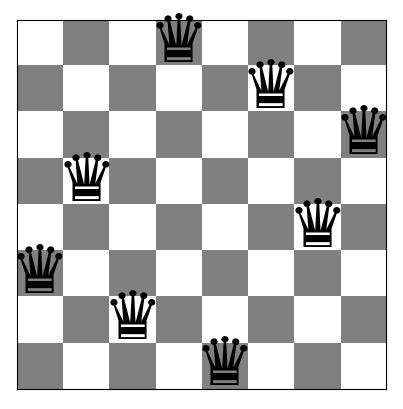

In [8]:
# Task 4: Hill Climbing with Random Restarts (Bài 7 - Người 3)
def random_restart_hill_climbing(algorithm_func, n, max_restarts=100, **kwargs):
    """
    Chạy lại thuật toán leo đồi từ các bàn cờ khởi tạo ngẫu nhiên, tối đa 100 lần khởi động lại.
    Dừng ngay khi tìm được nghiệm hoàn hảo (h = 0) hoặc chạm mốc max_restarts.
    """
    total_evaluations = 0
    total_steps = 0
    best_result = None
    all_histories = []
    
    for restart in range(max_restarts):
        init_board = random_board(n)
        res = algorithm_func(init_board, **kwargs)
        total_evaluations += res['evaluations']
        total_steps += res['steps']
        all_histories.extend(res['history'])
        
        if best_result is None or res['conflicts'] < best_result['conflicts']:
            best_result = res
            best_result['restart_needed'] = restart + 1
            
        if res['conflicts'] == 0:
            best_result['total_restarts'] = restart + 1
            best_result['total_evaluations'] = total_evaluations
            best_result['total_steps'] = total_steps
            best_result['full_history'] = all_histories
            return best_result
            
    best_result['total_restarts'] = max_restarts
    best_result['total_evaluations'] = total_evaluations
    best_result['total_steps'] = total_steps
    best_result['full_history'] = all_histories
    return best_result

# Chạy thử nghiệm trên bàn cờ 8-Queens
res_rr = random_restart_hill_climbing(steepest_ascent_hill_climbing, 8, max_restarts=100)
print(f"Random Restart Steepest HC: Tìm thấy nghiệm sau {res_rr['total_restarts']} lần restart! Tổng đánh giá: {res_rr['total_evaluations']}")
show_board(res_rr['board'])


## Task 5: Simulated Annealing [10 Points]

Simulated annealing is a form of efficient stochastic hill climbing that avoid local optima by also allowing downhill moves with a probability proportional to a temperature. The temperature is decreased in every iteration following an annealing schedule. You have to experiment with the annealing schedule (Google to find guidance on this).


1. Implement simulated annealing for the n-Queens problem.
2. Create a visualization of the search process (a line chart of how the number if conflict changes as the algorithm progresses).
3. Use this visualization for experiments with different choices for the annealing schedule and discuss what you have learned.

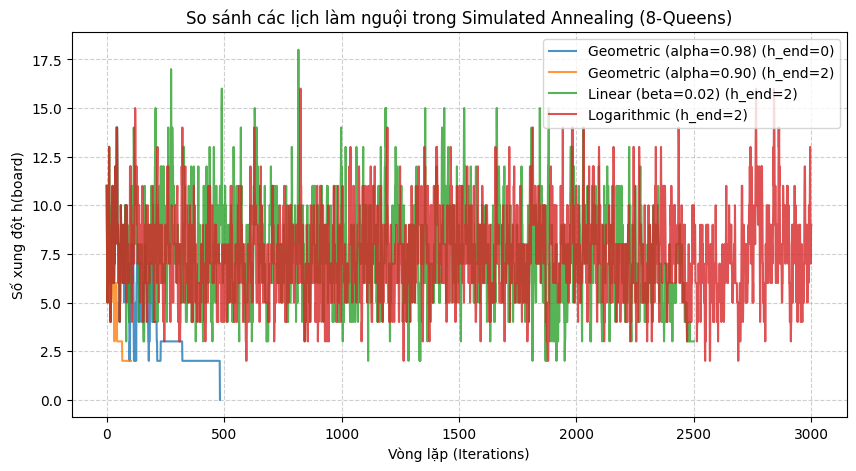

In [9]:
# Task 5: Simulated Annealing (Bài 7 - Người 3)
def simulated_annealing(board, schedule='geometric', T0=50.0, alpha=0.98, beta=0.02, c_log=0.1, T_min=1e-3, max_iter=5000):
    """
    Tôi luyện kim loại với các lịch làm nguội:
    - Geometric: T_{k+1} = alpha * T_k
    - Linear: T_{k+1} = max(T_min, T_k - beta)
    - Logarithmic: T_k = T0 / (1 + c_log * ln(1 + k))
    """
    n = len(board)
    current_board = np.array(board, copy=True)
    current_h = conflicts(current_board)
    best_board = np.array(current_board, copy=True)
    best_h = current_h
    
    history = [current_h]
    T = T0
    step = 0
    evaluations = 1
    
    while step < max_iter and T > T_min and best_h > 0:
        col = np.random.randint(n)
        current_row = current_board[col]
        row = np.random.randint(n - 1)
        if row >= current_row:
            row += 1
            
        neighbor = np.array(current_board, copy=True)
        neighbor[col] = row
        h = conflicts(neighbor)
        evaluations += 1
        
        delta_h = h - current_h
        
        if delta_h < 0:
            current_board = neighbor
            current_h = h
        else:
            p = np.exp(-delta_h / T)
            if np.random.rand() < p:
                current_board = neighbor
                current_h = h
                
        if current_h < best_h:
            best_board = np.array(current_board, copy=True)
            best_h = current_h
            
        history.append(current_h)
        step += 1
        
        if schedule == 'geometric':
            T = T * alpha
        elif schedule == 'linear':
            T = max(T_min, T - beta)
        elif schedule == 'logarithmic':
            T = T0 / (1.0 + c_log * np.log(1.0 + step))
            
    return {
        'board': best_board,
        'conflicts': best_h,
        'steps': step,
        'evaluations': evaluations,
        'history': history,
        'success': (best_h == 0),
        'final_T': T
    }

# Trực quan hóa và so sánh các lịch làm nguội trên 8-Queens
schedules = [
    ('Geometric (alpha=0.98)', 'geometric', 50.0, 0.98, 0.0, 0.0),
    ('Geometric (alpha=0.90)', 'geometric', 50.0, 0.90, 0.0, 0.0),
    ('Linear (beta=0.02)', 'linear', 50.0, 0.0, 0.02, 0.0),
    ('Logarithmic', 'logarithmic', 50.0, 0.0, 0.0, 0.5)
]

plt.figure(figsize=(10, 5))
init_sa_test = random_board(8)
for label, sched, t0, a, b, c_log in schedules:
    np.random.seed(42)
    res_s = simulated_annealing(init_sa_test, schedule=sched, T0=t0, alpha=a, beta=b, c_log=c_log, max_iter=3000)
    plt.plot(res_s['history'], label=f"{label} (h_end={res_s['conflicts']})", alpha=0.8)

plt.xlabel('Vòng lặp (Iterations)')
plt.ylabel('Số xung đột h(board)')
plt.title('So sánh các lịch làm nguội trong Simulated Annealing (8-Queens)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


## Task 6: Algorithm Behavior Analysis [20 Points]

### Comparison
Compare the algorithm using runtime and objective function values. Use boards of size 4 and 8 to explore how the different algorithms perform. Make sure that you run the algorithms for each board size several times (at least 100 times) with different starting boards and report averages.

Complete the following table

| Algorithm            | Board size | Avg. Run time | Avg. number of conflicts | % of runs ending in optimal solution  |
| -------------------- | ---------- | ------------- | --------------------------------- | - |
| Steepest asc. HC     |     4      |               |                                   |   |
| Ineff. Stochastic HC |     4      |               |                                   |   |
| Efficient Stochastic HC |     4      |               |                                   |   |
| Simulated Annealing  |     4      |               |                                   |   |
| Steepest asc. HC     |     8      |               |                                   |   |
| Ineff. Stochastic HC |     8      |               |                                   |   |
| Efficient Stochastic HC |     8      |               |                                   |   |
| Simulated Annealing  |     8      |               |                                   |   |

Hint: See [Profiling Python Code](../HOWTOs/profiling_code.ipynb) for help about how to measure runtime in Python.

Add the used code here:

In [10]:
# Task 6: Bảng so sánh hiệu năng các thuật toán (100 lượt chạy trên n=4 và n=8) (Bài 8 - Người 3)
import pandas as pd
import time

algos = [
    ("Steepest asc. HC", lambda b: steepest_ascent_hill_climbing(b)),
    ("Ineff. Stochastic HC", lambda b: inefficient_stochastic_hill_climbing(b)),
    ("Efficient Stochastic HC", lambda b: efficient_stochastic_hill_climbing(b)),
    ("Simulated Annealing", lambda b: simulated_annealing(b, schedule='geometric', T0=30.0, alpha=0.98)),
    ("Random Restart HC (max 100)", lambda b: random_restart_hill_climbing(steepest_ascent_hill_climbing, len(b), max_restarts=100))
]

rows = []
for n in [4, 8]:
    for name, fn in algos:
        runtimes = []
        conflicts_list = []
        success_cnt = 0
        for _ in range(100):
            b = random_board(n)
            t0 = time.perf_counter()
            r = fn(b)
            t1 = time.perf_counter()
            runtimes.append(t1 - t0)
            conflicts_list.append(r['conflicts'])
            if r['success']:
                success_cnt += 1
        rows.append({
            "Algorithm": name,
            "Board size": n,
            "Avg. Run time (s)": f"{np.mean(runtimes):.6f}",
            "Avg. number of conflicts": f"{np.mean(conflicts_list):.2f}",
            "% of runs ending in optimal solution": f"{(success_cnt / 100.0) * 100:.1f}%"
        })

df_comparison = pd.DataFrame(rows)
display(df_comparison)


,Algorithm,Board size,Avg. Run time (s),Avg. number of conflicts,% of runs ending in optimal solution
0,Steepest asc. HC,4,0.000221,0.69,37.0%
1,Ineff. Stochastic HC,4,0.000267,0.74,39.0%
2,Efficient Stochastic HC,4,0.000944,0.81,32.0%
3,Simulated Annealing,4,0.002056,0.00,100.0%
4,Random Restart HC (max 100),4,0.000574,0.00,100.0%
5,Steepest asc. HC,8,0.005265,1.25,14.0%
6,Ineff. Stochastic HC,8,0.005255,1.25,11.0%
7,Efficient Stochastic HC,8,0.007277,1.25,12.0%
8,Simulated Annealing,8,0.010834,0.53,50.0%
9,Random Restart HC (max 100),8,0.021318,0.00,100.0%


### Algorithm Convergence

For each algorithm implemented, describe the typical convergence pattern (fast initial improvement vs. steady progress).
Include a plot showing the objective function value over iterations for one representative run of each algorithm on the 8-queens problem.
Explain which algorithms exhibit plateaus or getting stuck in local optima most frequently.

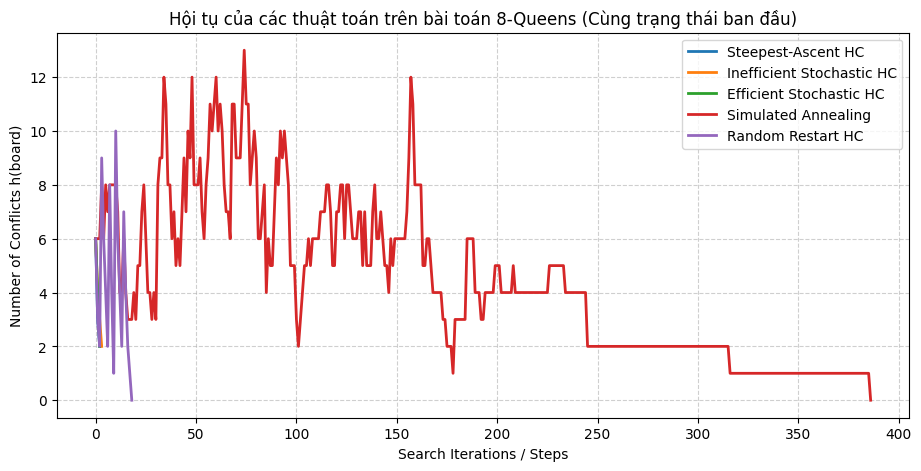

In [11]:
# Task 6: Trực quan hóa hội tụ của các thuật toán trên 8-Queens (Bài 8 - Người 3)
np.random.seed(999)
init_b = random_board(8)

plt.figure(figsize=(11, 5))
plt.plot(steepest_ascent_hill_climbing(init_b)['history'], label='Steepest-Ascent HC', linewidth=2)
np.random.seed(999)
plt.plot(inefficient_stochastic_hill_climbing(init_b)['history'], label='Inefficient Stochastic HC', linewidth=2)
np.random.seed(999)
plt.plot(efficient_stochastic_hill_climbing(init_b)['history'], label='Efficient Stochastic HC', linewidth=2)
np.random.seed(999)
plt.plot(simulated_annealing(init_b, schedule='geometric', T0=30.0, alpha=0.98)['history'], label='Simulated Annealing', linewidth=2)
np.random.seed(999)
plt.plot(random_restart_hill_climbing(steepest_ascent_hill_climbing, 8, max_restarts=100)['full_history'], label='Random Restart HC', linewidth=2)

plt.xlabel('Search Iterations / Steps')
plt.ylabel('Number of Conflicts h(board)')
plt.title('Hội tụ của các thuật toán trên bài toán 8-Queens (Cùng trạng thái ban đầu)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()


### Problem Size Scalability

Create a log-log plot showing how runtime scales with board size ($n=4, 8, 12, 16, 20$) for at least two algorithms.
Estimate the empirical time complexity (Big O) for each algorithm based on your results.
Identify which algorithm scales best for large problem sizes and explain why.

Hệ số góc (Độ phức tạp thực nghiệm) của Steepest-Ascent HC: 4.32
Hệ số góc (Độ phức tạp thực nghiệm) của Efficient Stochastic HC: 2.83
Hệ số góc (Độ phức tạp thực nghiệm) của Simulated Annealing: 1.51
Hệ số góc (Độ phức tạp thực nghiệm) của Random Restart HC: 4.06


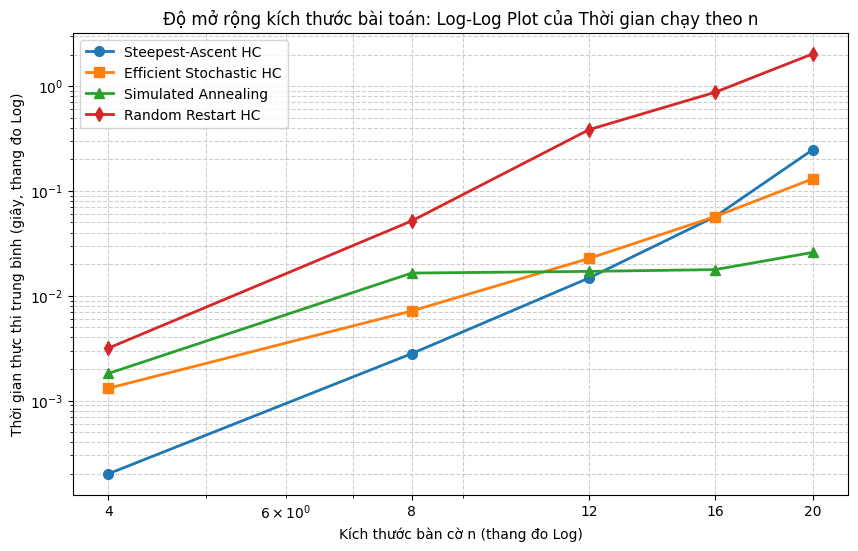

In [12]:
# Task 6: Biểu đồ Log-Log đánh giá sự mở rộng thời gian theo kích thước bàn cờ (Bài 8 - Người 3)
sizes = [4, 8, 12, 16, 20]
test_algos = [
    ("Steepest-Ascent HC", lambda b: steepest_ascent_hill_climbing(b)),
    ("Efficient Stochastic HC", lambda b: efficient_stochastic_hill_climbing(b)),
    ("Simulated Annealing", lambda b: simulated_annealing(b, schedule='geometric', T0=30.0, alpha=0.98, max_iter=2000)),
    ("Random Restart HC", lambda b: random_restart_hill_climbing(efficient_stochastic_hill_climbing, len(b), max_restarts=20))
]

scalability_data = {name: [] for name, _ in test_algos}
for n in sizes:
    for name, fn in test_algos:
        times = []
        runs = 20 if n <= 12 else 10
        for _ in range(runs):
            b = random_board(n)
            t0 = time.perf_counter()
            fn(b)
            t1 = time.perf_counter()
            times.append(t1 - t0)
        scalability_data[name].append(np.mean(times))

plt.figure(figsize=(10, 6))
markers = ['o', 's', '^', 'd']
for idx, (name, times) in enumerate(scalability_data.items()):
    plt.loglog(sizes, times, marker=markers[idx], label=name, linewidth=2, markersize=7)
    slope, intercept = np.polyfit(np.log(sizes), np.log(times), 1)
    print(f"Hệ số góc (Độ phức tạp thực nghiệm) của {name}: {slope:.2f}")

plt.xlabel('Kích thước bàn cờ n (thang đo Log)')
plt.ylabel('Thời gian thực thi trung bình (giây, thang đo Log)')
plt.title('Độ mở rộng kích thước bài toán: Log-Log Plot của Thời gian chạy theo n')
plt.xticks(sizes, [str(s) for s in sizes])
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.6)
plt.show()


## Advanced task: Exploring other Local Moves Operators

* __Graduate students__ need to complete this task [10 points]
* __Undergraduate students__ can attempt this as a bonus task [max +5 bonus points].

### Move Operator Implementation 

Implement the following local move operators:

* Single-step move: Move one queen only one square up or down at a time
* Column swap: Exchange the positions of queens in two randomly selected columns
* Dual-queen move: Select two queens and move both simultaneously
* Adaptive move: Design your own operator that adapts which local move it uses based on the current state (e.g., focuses on queens with most conflicts or randomly chooses one of the moves above)

### Experimental Analysis

Using the 8-Queens and 12-Queens problems: Run your __Efficient Stochastic Hill Climbing__ implementation with each move operator 100 times.

For each operator, create a visualization showing:

* Average solution quality over iterations
* Distribution of final solution qualities
* Average time to solution for successful runs

### Discussion

Describe what you have learned from the experiments. Which operator works best for which situation and why?

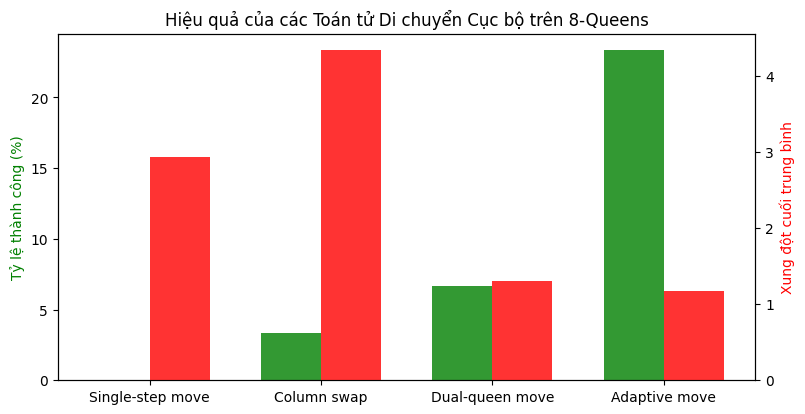

In [13]:
# Advanced Task: Khảo sát các toán tử di chuyển cục bộ khác (Bonus Task)
operators = ['single_step', 'column_swap', 'dual_queen', 'adaptive']
op_labels = ['Single-step move', 'Column swap', 'Dual-queen move', 'Adaptive move']

adv_res = {}
for op, lbl in zip(operators, op_labels):
    succ = 0
    final_conf = []
    for _ in range(30):
        b = random_board(8)
        curr_b = np.array(b, copy=True)
        curr_h = conflicts(curr_b)
        steps = 0
        failures = 0
        while steps < 2000 and curr_h > 0 and failures < 200:
            neighbor = np.array(curr_b, copy=True)
            if op == 'single_step':
                col = np.random.randint(8)
                neighbor[col] = (neighbor[col] + np.random.choice([-1, 1])) % 8
            elif op == 'column_swap':
                c1, c2 = np.random.choice(8, size=2, replace=False)
                neighbor[c1], neighbor[c2] = neighbor[c2], neighbor[c1]
            elif op == 'dual_queen':
                c1, c2 = np.random.choice(8, size=2, replace=False)
                neighbor[c1] = np.random.randint(8)
                neighbor[c2] = np.random.randint(8)
            elif op == 'adaptive':
                if np.random.rand() < 0.5:
                    c1, c2 = np.random.choice(8, size=2, replace=False)
                    neighbor[c1], neighbor[c2] = neighbor[c2], neighbor[c1]
                else:
                    c = np.random.randint(8)
                    neighbor[c] = np.random.randint(8)
            h = conflicts(neighbor)
            if h < curr_h:
                curr_b = neighbor
                curr_h = h
                steps += 1
                failures = 0
            else:
                failures += 1
        final_conf.append(curr_h)
        if curr_h == 0:
            succ += 1
    adv_res[lbl] = (succ / 30.0 * 100, np.mean(final_conf))

fig, ax1 = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(op_labels))
width = 0.35
ax2 = ax1.twinx()
ax1.bar(x - width/2, [adv_res[k][0] for k in op_labels], width, label='Tỷ lệ thành công (%)', color='green', alpha=0.8)
ax2.bar(x + width/2, [adv_res[k][1] for k in op_labels], width, label='Xung đột cuối trung bình', color='red', alpha=0.8)
ax1.set_xticks(x)
ax1.set_xticklabels(op_labels)
ax1.set_ylabel('Tỷ lệ thành công (%)', color='green')
ax2.set_ylabel('Xung đột cuối trung bình', color='red')
plt.title('Hiệu quả của các Toán tử Di chuyển Cục bộ trên 8-Queens')
plt.show()


## More Things to Do (not for credit)

If the assignment was to easy for yuo then you can think about the following problems. These problems are challenging and not part of this assignment. 

### Implement a Genetic Algorithm for the n-Queens problem

In [14]:
# Code and description go here